#**Assignment 4 - Part 2: Fine-Tuning the GPT2 Language Model for Sentiment Analysis of IMDb Users**

>Mohammad Amin Rafiei

>saba Heidaridoost

In [1]:
# Update libraries
!pip install --upgrade datasets fsspec torchvision transformers torch scikit-learn matplotlib seaborn peft

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.2/40.2 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 28.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 18.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 87.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 865.2/865.2 MB 795.5 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 393.1/393.1 MB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 126.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 87.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 897.7/897.7 kB 57.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 571.0/571.0 MB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.2/200.2 MB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 64.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5

In [2]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from transformers import (
    GPT2Tokenizer, GPT2LMHeadModel, GPT2Config,
    TrainingArguments, Trainer, AutoModelForSequenceClassification,
    AutoTokenizer, get_linear_schedule_with_warmup
)
from datasets import load_dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from tqdm import tqdm
import warnings

In [3]:
warnings.filterwarnings('ignore')

In [4]:
# تنظیم device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


#2.1 GPT2 paper

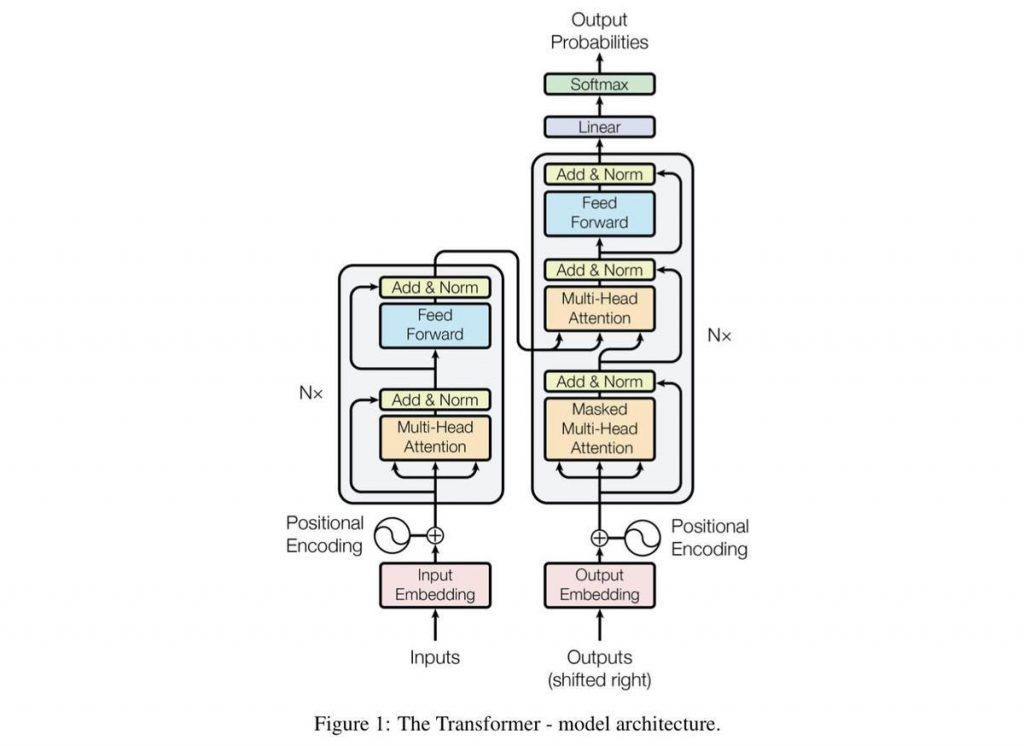

GPT-2 (Generative Pretrained Transformer 2) is a large-scale, unsupervised language model developed by OpenAI. It is based on the Transformer architecture, which relies entirely on self-attention mechanisms to model relationships between words in a sequence. GPT-2 uses a decoder-only Transformer with masked self-attention to enable autoregressive generation—predicting the next token given previous ones.

The model is trained on a massive corpus of web text (WebText), using a language modeling objective: maximizing the likelihood of a token given its leftward context. It does not rely on task-specific data during pretraining. Instead, it generalizes to downstream tasks such as question answering, translation, and summarization via zero-shot, one-shot, or few-shot learning, based solely on how prompts are framed.

GPT-2 comes in multiple sizes, with the largest containing 1.5 billion parameters. Its architecture includes 48 layers, 1600 hidden units, and 25 attention heads per layer. It uses byte pair encoding (BPE) for tokenization, enabling it to handle diverse and noisy text input.

Despite being autoregressive and unidirectional, GPT-2 achieves strong performance across various benchmarks, highlighting the power of large-scale pretraining and transfer learning in NLP. However, its lack of grounding and factual consistency remain limitations.



## **1. How does the Unidirectional Attention architecture in GPT work?**

GPT (Generative Pre-trained Transformer) uses a **unidirectional attention mechanism**, which means that at any given point in the sequence, the model can only attend to tokens that come **before or at the current position**—not after. This is a fundamental design choice that aligns GPT with the task of **language modeling** and **text generation**, where predicting the next word must be done based only on the preceding context.

Here’s how it works:

* **Transformer Decoder Structure**:
  GPT is based on the decoder component of the original Transformer architecture. Unlike the encoder (used in BERT), which has full bidirectional access, the decoder restricts attention to past tokens.

* **Causal Masking (aka Look-ahead Masking)**:
  In each self-attention layer, GPT applies a *causal mask* to ensure that the model only considers tokens from the left (i.e., earlier in the sequence). This is implemented using a **triangular mask** that blocks future positions during attention computation.

* **Sequential Processing**:
  Although the model is trained in parallel over sequences, the attention mechanism ensures that each token can only “see” earlier ones, effectively simulating a left-to-right generation process.

* **Motivation and Realism**:
  This unidirectional setup closely mirrors how language is naturally produced—word by word, with no access to future input. It enables GPT to generate coherent and contextually appropriate text by predicting one token at a time based on all prior context.

---



## **2. What are the key differences between GPT and BERT architectures?**

GPT and BERT are both built on the Transformer framework but are designed with fundamentally different goals and architectural strategies:

  **Directionality:**

* **GPT** is *unidirectional (left-to-right)*. It can only use the previous context when predicting the next token.
* **BERT** is *bidirectional*. It can access both past and future tokens simultaneously thanks to its masked token prediction strategy.

  **Transformer Component Used:**

* **GPT** uses the **Transformer decoder** (with masked self-attention).
* **BERT** uses the **Transformer encoder** (with full self-attention).

  **Pre-training Objectives:**

* **GPT** is trained with a **causal language modeling** objective: predict the next word given all previous ones.
* **BERT** is trained with two tasks:

  * **Masked Language Modeling (MLM)**: Randomly masks tokens and predicts them.
  * **Next Sentence Prediction (NSP)**: Determines whether one sentence logically follows another.

  **Strengths by Task Type:**

* **GPT** excels at **text generation**, **story completion**, **dialogue modeling**, and **few-shot learning**.
* **BERT** is better suited for **text classification**, **sentiment analysis**, **question answering**, and **other comprehension tasks**.

  **Usage Style:**

* **GPT** is often used in **zero-shot or few-shot settings** (especially GPT-3 and beyond) using task-specific prompts.
* **BERT** typically requires **fine-tuning** for each specific downstream task, adjusting its weights based on task-specific data.

  **Model Behavior:**

* GPT can naturally generate long-form content without needing special tokens like `[MASK]`, while BERT cannot generate coherent text beyond token recovery due to its masked input.

---

## **3. How are GPT models pre-trained and fine-tuned?**

  **Pre-training in GPT:**

* **Objective**: GPT is pre-trained using the **causal language modeling** task. The goal is to predict the next word in a sentence given all the previous words. For example, given "The cat sat on the", the model should predict "mat".

* **Training Data**: GPT models are trained on massive corpora of natural language text (e.g., books, articles, websites) to develop a deep understanding of language patterns, grammar, and context.

* **Architecture During Pre-training**: The model uses only a decoder stack of Transformer blocks, each with masked self-attention to enforce unidirectional prediction.

* **No Supervision Required**: Pre-training is unsupervised, relying solely on raw text data without labeled outputs.

  **Fine-tuning GPT for Downstream Tasks:**

* **Adding a Classification Head**: For tasks like sentiment analysis or question classification, a simple linear layer (classification head) is added on top of the model’s final token representations.

* **Training Approach**:

  * The model is further trained (fine-tuned) on labeled data specific to the downstream task.
  * During fine-tuning, the full model or only a subset of layers (e.g., just the classification head) can be trained.
  * In many setups, lower layers are **frozen** to retain general language understanding, while only upper layers are updated to adapt to the specific task.

* **Prompt-based Learning (in later GPT versions)**: In larger GPT models like GPT-3, **prompt engineering** is used instead of traditional fine-tuning. The model is given carefully designed prompts that describe the task, allowing it to perform tasks in a few-shot or even zero-shot manner without any weight updates.

  **Considerations**:

* Fine-tuning smaller GPT models (like GPT-2) can be efficient but may require task-specific architecture changes.
* Larger GPT models (like GPT-3 or GPT-4) can achieve strong performance with just prompting, reducing the need for separate fine-tuning.


#2.2 Preprocessing

load imdb dataset.

In [5]:
dataset = load_dataset("imdb")

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

train-00000-of-00001.parquet:   0%|          | 0.00/21.0M [00:00<?, ?B/s]

test-00000-of-00001.parquet:   0%|          | 0.00/20.5M [00:00<?, ?B/s]

unsupervised-00000-of-00001.parquet:   0%|          | 0.00/42.0M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

**Class distribution analysis**

1. Extracts the labels for training and testing data.

2. Prints the total number of samples in both the training and test sets.

3. Calculates and prints how many samples belong to each class (Negative = 0, Positive = 1) in both sets.

In [6]:
# Class distribution analysis
train_labels = np.array(dataset['train']['label'])
test_labels = np.array(dataset['test']['label'])

print(f"Total number of train samples: {len(dataset['train'])}")
print(f"Total number of test samples: {len(dataset['test'])}")
print(f"Class distribution in train - Negative: {np.sum(train_labels == 0)}, Positive: {np.sum(train_labels == 1)}")
print(f"Class distribution in test - Negative: {np.sum(test_labels == 0)}, Positive: {np.sum(test_labels == 1)}")

Total number of train samples: 25000
Total number of test samples: 25000
Class distribution in train - Negative: 12500, Positive: 12500
Class distribution in test - Negative: 12500, Positive: 12500


Text Length Stats: Calculates word counts for each text in the training and test sets, then prints summary statistics (mean, median, max, min).

In [7]:
train_lengths = [len(text.split()) for text in dataset['train']['text']]
test_lengths = [len(text.split()) for text in dataset['test']['text']]

print(f"\nText length statistics (train):")
print(f"Mean: {np.mean(train_lengths):.2f}")
print(f"Median: {np.median(train_lengths):.2f}")
print(f"Max: {np.max(train_lengths)}")
print(f"Min: {np.min(train_lengths)}")


Text length statistics (train):
Mean: 233.79
Median: 174.00
Max: 2470
Min: 10


Sample Display: Prints the first 200 characters of the first training text and its label.

In [8]:
print(f"\nSample raw data:")
print(f"Text: {dataset['train']['text'][0][:200]}...")
print(f"Label: {dataset['train']['label'][0]} ({'positive' if dataset['train']['label'][0] == 1 else 'negative'})")


Sample raw data:
Text: I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ev...
Label: 0 (negative)


Subsampling: Selects a smaller portion (5,000 for training and 1,000 for testing) to speed up processing.

In [9]:
TRAIN_SIZE = 5000
TEST_SIZE = 1000

dataset['train'] = dataset['train'].shuffle(seed=42).select(range(TRAIN_SIZE))
dataset['test'] = dataset['test'].shuffle(seed=42).select(range(TEST_SIZE))

train_texts = dataset['train']['text']
train_labels = dataset['train']['label']
test_texts = dataset['test']['text']
test_labels = dataset['test']['label']

print(f"\nAfter shuffling and subsampling:")
print(f"Number of train samples: {len(train_texts)}")
print(f"Number of test samples: {len(test_texts)}")


After shuffling and subsampling:
Number of train samples: 5000
Number of test samples: 1000


formats the training and test data into a human-readable structure

In [10]:
# Data formatting
def format_data(text, label):
    label_text = "positive" if label == 1 else "negative"
    return f"Review: {text}\nSentiment: {label_text}"

In [11]:
# Convert to the desired format
formatted_train = [format_data(text, label) for text, label in zip(train_texts, train_labels)]
formatted_test = [format_data(text, label) for text, label in zip(test_texts, test_labels)]

print(f"\nFormatted sample data:")
print(formatted_train[0][:300])


Formatted sample data:
Review: There is no relation at all between Fortier and Profiler but the fact that both are police series about violent crimes. Profiler looks crispy, Fortier looks classic. Profiler plots are quite simple. Fortier's plot are far more complicated... Fortier looks more like Prime Suspect, if we have 


**tokenizer**

prepares text data for use with a GPT-2 model by tokenizing it:

1. Tokenizer Setup: Loads the GPT-2 tokenizer and sets the padding token to the EOS (end of sequence) token.

2. tokenize_function:

 - Truncates long texts to a maximum length (default: 512 characters).

 - Applies the tokenizer with truncation and padding.

 - Returns PyTorch tensors.

3. Tokenizing Data: Applies the function to the formatted training and test texts.

In [12]:
# Load tokenizer
tokenizer = GPT2Tokenizer.from_pretrained("gpt2")
tokenizer.pad_token = tokenizer.eos_token

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

In [13]:
# Tokenization function
def tokenize_function(examples, max_length=512):
    # Truncate text for speed
    truncated_examples = [ex[:max_length] for ex in examples]

    tokenized = tokenizer(
        truncated_examples,
        truncation=True,
        padding=True,
        max_length=max_length,
        return_tensors="pt"
    )

    return tokenized

In [14]:
# Tokenize the data
print("Tokenizing data...")
train_encodings = tokenize_function(formatted_train)
test_encodings = tokenize_function(formatted_test)

print(f"Shape of train encodings: {train_encodings['input_ids'].shape}")
print(f"Shape of test encodings: {test_encodings['input_ids'].shape}")

Tokenizing data...
Shape of train encodings: torch.Size([5000, 224])
Shape of test encodings: torch.Size([1000, 148])


1. Custom Dataset Class:

 - SentimentDataset subclasses torch.utils.data.Dataset.

 - Converts the tokenized inputs and labels into tensors.

 - Implements __getitem__ for indexing and __len__ to return the dataset size.

2. Creating Dataset Objects:

 - Wraps the training and test encodings and labels into PyTorch datasets.

3. Creating DataLoaders:

 - Creates DataLoader objects for batch processing.

 - Training data is shuffled for better generalization; test data is not shuffled.

In [15]:
class SentimentDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

    def __len__(self):
        return len(self.labels)

In [16]:
# Create datasets
train_dataset = SentimentDataset(train_encodings, train_labels)
test_dataset = SentimentDataset(test_encodings, test_labels)

In [17]:
# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False)

In [18]:
print(f"Number of train batches: {len(train_loader)}")
print(f"Number of test batches: {len(test_loader)}")

Number of train batches: 625
Number of test batches: 125


#2.3 Model Implementation


### **Custom Sentiment Classification Model Using GPT-2**

This class defines a sentiment classification model by customizing the base **GPT-2** architecture from Hugging Face.

#### **1. Initialization (`__init__` method):**

* **Base Model Loading**: Loads the pretrained GPT-2 model using `GPT2LMHeadModel.from_pretrained`.
* **Freezing Weights** *(optional)*: If `freeze_base=True`, all base GPT-2 parameters are frozen to prevent their updates during training.
* **Classifier Layer**: A dropout layer is applied for regularization, followed by a linear layer mapping GPT-2’s hidden size to `num_labels` (e.g., 2 for binary sentiment).
* **Weight Initialization**: Classifier weights are initialized with a normal distribution and biases are set to zero.

#### **2. Forward Pass (`forward` method):**

* **Input Processing**: Takes `input_ids` and `attention_mask` to get the output from GPT-2’s transformer.
* **Feature Extraction**: Extracts the last token's hidden state from `last_hidden_state`, simulating the \[CLS] token used in BERT-like models.
* **Classification**: Passes this pooled representation through dropout and the classifier to produce `logits`.
* **Loss Calculation**: If `labels` are provided, computes cross-entropy loss.

#### **Output**: Returns a dictionary containing the loss, predicted logits, and hidden states.


In [19]:
# Custom classification model class
class GPT2ForSentimentClassification(nn.Module):
    def __init__(self, model_name="gpt2", num_labels=2, freeze_base=True):
        super().__init__()

        # Load base GPT-2 model
        self.gpt2 = GPT2LMHeadModel.from_pretrained(model_name)
        self.config = self.gpt2.config

        # Freeze base model layers
        if freeze_base:
            for param in self.gpt2.parameters():
                param.requires_grad = False
            print("Base GPT-2 layers frozen")

        # Classification layer
        self.dropout = nn.Dropout(0.1)
        self.classifier = nn.Linear(self.config.hidden_size, num_labels)

        # Weight initialization
        nn.init.normal_(self.classifier.weight, std=0.02)
        nn.init.zeros_(self.classifier.bias)

    def forward(self, input_ids, attention_mask=None, labels=None):
        # Get hidden states from GPT-2 transformer
        outputs = self.gpt2.transformer(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        # Use the last token’s hidden state for classification
        hidden_states = outputs.last_hidden_state
        pooled_output = hidden_states[:, -1, :]  # [CLS]-equivalent

        # Classification
        pooled_output = self.dropout(pooled_output)
        logits = self.classifier(pooled_output)

        loss = None
        if labels is not None:
            loss_fct = nn.CrossEntropyLoss()
            loss = loss_fct(logits, labels)

        return {
            'loss': loss,
            'logits': logits,
            'hidden_states': hidden_states
        }

In [20]:
# Create model
model = GPT2ForSentimentClassification(freeze_base=True)
model.to(device)

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Base GPT-2 layers frozen


GPT2ForSentimentClassification(
  (gpt2): GPT2LMHeadModel(
    (transformer): GPT2Model(
      (wte): Embedding(50257, 768)
      (wpe): Embedding(1024, 768)
      (drop): Dropout(p=0.1, inplace=False)
      (h): ModuleList(
        (0-11): 12 x GPT2Block(
          (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
          (attn): GPT2Attention(
            (c_attn): Conv1D(nf=2304, nx=768)
            (c_proj): Conv1D(nf=768, nx=768)
            (attn_dropout): Dropout(p=0.1, inplace=False)
            (resid_dropout): Dropout(p=0.1, inplace=False)
          )
          (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
          (mlp): GPT2MLP(
            (c_fc): Conv1D(nf=3072, nx=768)
            (c_proj): Conv1D(nf=768, nx=3072)
            (act): NewGELUActivation()
            (dropout): Dropout(p=0.1, inplace=False)
          )
        )
      )
      (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
    )
    (lm_head): Linear(in_features=

In [21]:
print(f"Model moved to {device}")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")
print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")

Model moved to cuda
Trainable parameters: 1,538
Total parameters: 124,441,346


**Hyperparameter settings**

In [26]:
# Hyperparameter settings
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-5, weight_decay=0.01)
num_epochs = 15
num_training_steps = len(train_loader) * num_epochs
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=0,
    num_training_steps=num_training_steps
)

print(f"Training settings:")
print(f"Learning rate: 5e-5")
print(f"Epochs: {num_epochs}")
print(f"Batch size: 8")
print(f"Weight decay: 0.01")

Training settings:
Learning rate: 5e-5
Epochs: 15
Batch size: 8
Weight decay: 0.01


Model Training Function


### **Training Function: `train_epoch`**

The `train_epoch` function performs one full training pass (epoch) over the training dataset using a PyTorch model.

#### **1. Mode Setting**

* **`model.train()`**: Sets the model to training mode, enabling features like dropout and gradient computation.

#### **2. Initialization**

* Initializes cumulative metrics:

  * `total_loss`: Sum of batch losses.
  * `correct_predictions` & `total_predictions`: For calculating accuracy.

#### **3. Training Loop**

* **Iteration**: Loops over batches using a DataLoader, with progress displayed via `tqdm`.
* **Data Transfer**: Moves `input_ids`, `attention_mask`, and `labels` to the target `device` (CPU/GPU).
* **Gradient Reset**: `optimizer.zero_grad()` clears previous gradients.
* **Forward Pass**: Passes inputs through the model to get `logits` and `loss`.
* **Backward Pass**:

  * Computes gradients: `loss.backward()`
  * Clips gradients to avoid exploding gradients: `clip_grad_norm_`
  * Updates weights with `optimizer.step()` and learning rate with `scheduler.step()`.
* **Prediction and Metrics**:

  * Calculates predictions via `argmax`.
  * Updates count of correct and total predictions.
  * Adds batch loss to `total_loss`.

#### **4. Final Metrics**

* **Average Loss** and **Accuracy** are computed and returned for the epoch.



In [23]:
def train_epoch(model, train_loader, optimizer, scheduler, device):
    model.train()
    total_loss = 0
    correct_predictions = 0
    total_predictions = 0

    for batch in tqdm(train_loader, desc="Training"):
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs['loss']
        logits = outputs['logits']

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()

        predictions = torch.argmax(logits, dim=-1)
        correct_predictions += (predictions == labels).sum().item()
        total_predictions += labels.size(0)
        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    accuracy = correct_predictions / total_predictions

    return avg_loss, accuracy

Model Evaluation Function


### **Model Evaluation: `evaluate_model`**

This function evaluates a trained model on a test dataset.

* **Mode Setting**: `model.eval()` disables dropout and gradient updates.
* **Metrics Initialization**: Tracks total loss, predictions, labels, and logits.
* **No Gradient Calculation**: `torch.no_grad()` improves memory and speed.
* **Batch Loop**:

  * Inputs are moved to the target device.
  * The model generates logits and computes loss.
  * Predictions are obtained via `argmax`.
  * Results are stored for later analysis.
* **Final Metrics**:

  * Calculates average loss over batches.
  * Computes overall accuracy using `accuracy_score`.

Returns: loss, accuracy, predictions, true labels, and logits.

In [24]:
def evaluate_model(model, test_loader, device):
    model.eval()
    total_loss = 0
    all_predictions = []
    all_labels = []
    all_logits = []

    with torch.no_grad():
        for batch in tqdm(test_loader, desc="Evaluating"):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            loss = outputs['loss']
            logits = outputs['logits']

            total_loss += loss.item()
            predictions = torch.argmax(logits, dim=-1)
            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_logits.extend(logits.cpu().numpy())

    avg_loss = total_loss / len(test_loader)
    accuracy = accuracy_score(all_labels, all_predictions)

    return avg_loss, accuracy, all_predictions, all_labels, all_logits

The training loop runs for a defined number of epochs. In each epoch, it trains the model using `train_epoch`, evaluates it with `evaluate_model`, and stores the losses and accuracies. Progress is printed after each epoch, showing both training and validation performance to monitor learning and generalization.

In [27]:
train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

for epoch in range(num_epochs):
    print(f"\nEpoch {epoch + 1}/{num_epochs}")

    train_loss, train_acc = train_epoch(model, train_loader, optimizer, scheduler, device)
    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    val_loss, val_acc, _, _, _ = evaluate_model(model, test_loader, device)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")


Epoch 1/15


Evaluating: 100%|██████████| 125/125 [00:08<00:00, 14.10it/s]


Train Loss: 0.7093, Train Acc: 0.5222
Val Loss: 0.6838, Val Acc: 0.4900

Epoch 2/15


Evaluating: 100%|██████████| 125/125 [00:08<00:00, 14.02it/s]


Train Loss: 0.6883, Train Acc: 0.5466
Val Loss: 0.6730, Val Acc: 0.6410

Epoch 3/15


Evaluating: 100%|██████████| 125/125 [00:08<00:00, 14.02it/s]


... (21 outputs left out)

Evaluating: 100%|██████████| 125/125 [00:08<00:00, 13.97it/s]


Train Loss: 0.6399, Train Acc: 0.6918
Val Loss: 0.6384, Val Acc: 0.7390

Epoch 15/15


Evaluating: 100%|██████████| 125/125 [00:08<00:00, 14.06it/s]

Train Loss: 0.6386, Train Acc: 0.6966
Val Loss: 0.6383, Val Acc: 0.7460


#2.4 Evaluation and analysis of results

Evaluating: 100%|██████████| 125/125 [00:09<00:00, 13.31it/s]


final result:
Accuracy: 0.7460
Precision: 0.7462
Recall: 0.7460
F1-Score: 0.7457
Perplexity: 1.8933

Confusion Matrix:
[[396 116]
 [138 350]]


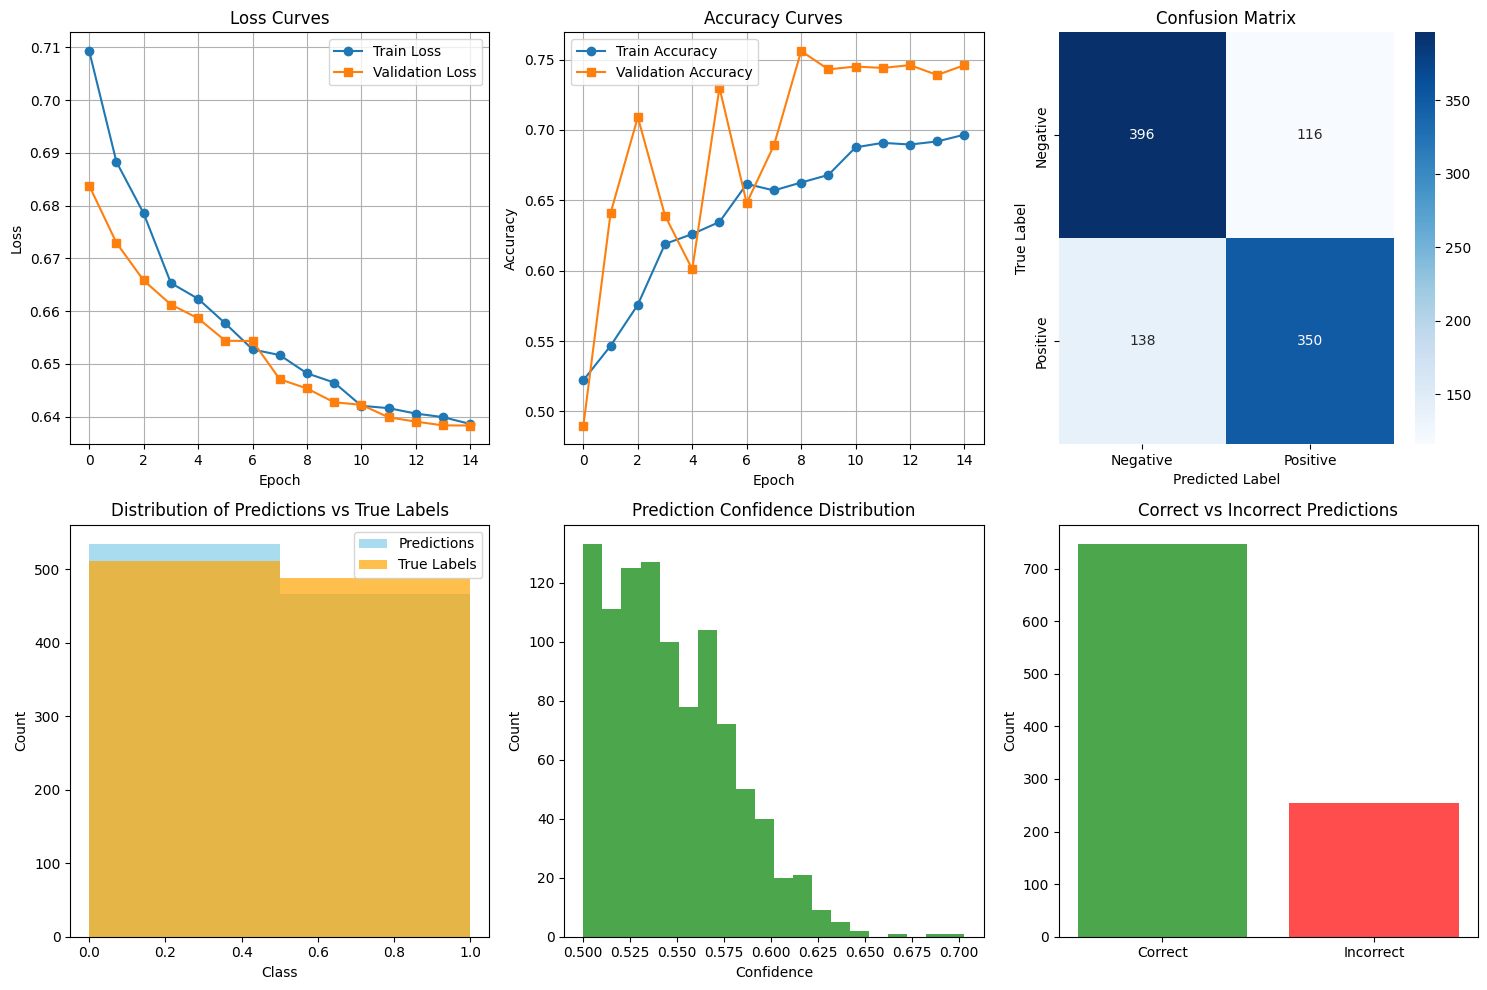

In [28]:
# final evaluation
final_loss, final_accuracy, predictions, true_labels, logits = evaluate_model(model, test_loader, device)

# other
precision, recall, f1, _ = precision_recall_fscore_support(true_labels, predictions, average='weighted')

print(f"final result:")
print(f"Accuracy: {final_accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")

# Perplexity
perplexity = np.exp(final_loss)
print(f"Perplexity: {perplexity:.4f}")

# Confusion Matrix
cm = confusion_matrix(true_labels, predictions)
print(f"\nConfusion Matrix:")
print(cm)

# show result
plt.figure(figsize=(15, 10))

# Loss curves
plt.subplot(2, 3, 1)
plt.plot(train_losses, label='Train Loss', marker='o')
plt.plot(val_losses, label='Validation Loss', marker='s')
plt.title('Loss Curves')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Accuracy curves
plt.subplot(2, 3, 2)
plt.plot(train_accuracies, label='Train Accuracy', marker='o')
plt.plot(val_accuracies, label='Validation Accuracy', marker='s')
plt.title('Accuracy Curves')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Confusion Matrix
plt.subplot(2, 3, 3)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'])
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')

# Distribution of predictions
plt.subplot(2, 3, 4)
plt.hist(predictions, bins=2, alpha=0.7, label='Predictions', color='skyblue')
plt.hist(true_labels, bins=2, alpha=0.7, label='True Labels', color='orange')
plt.title('Distribution of Predictions vs True Labels')
plt.xlabel('Class')
plt.ylabel('Count')
plt.legend()

# Prediction confidence
logits_array = np.array(logits)
probabilities = torch.softmax(torch.tensor(logits_array), dim=-1).numpy()
confidence = np.max(probabilities, axis=1)

plt.subplot(2, 3, 5)
plt.hist(confidence, bins=20, alpha=0.7, color='green')
plt.title('Prediction Confidence Distribution')
plt.xlabel('Confidence')
plt.ylabel('Count')

# Sample predictions
plt.subplot(2, 3, 6)
correct_preds = np.array(predictions) == np.array(true_labels)
plt.bar(['Correct', 'Incorrect'],
        [np.sum(correct_preds), np.sum(~correct_preds)],
        color=['green', 'red'], alpha=0.7)
plt.title('Correct vs Incorrect Predictions')
plt.ylabel('Count')

plt.tight_layout()
plt.show()


**Question: What are the key differences between the GPT and BERT architectures?**

**Answer:**

The GPT (Generative Pre-trained Transformer) and BERT (Bidirectional Encoder Representations from Transformers) models represent two different approaches to leveraging transformers for natural language processing tasks. Below are the key differences between them:

---

### 1. **Architecture**

* **GPT:**

  * Based on a *decoder-only*, autoregressive transformer architecture.
  * Processes text in a left-to-right (causal) manner.
  * Optimized for *text generation* by predicting the next token in a sequence.

* **BERT:**

  * Built on a *bidirectional encoder-only* transformer.
  * Reads the entire sequence at once, allowing it to consider both left and right context.
  * Optimized for *understanding* tasks rather than generation.

---

### 2. **Usage in Downstream Tasks**

* **GPT:**

  * Uses the final hidden state of the last token for classification tasks.
  * Requires task-specific prompting or architecture adaptation (e.g., adding a classification head).

* **BERT:**

  * Introduces a special `[CLS]` token whose output embedding is used for classification.
  * Provides a more structured approach to fine-tuning for supervised tasks.

---

### 3. **Pre-training Objectives**

* **GPT:**

  * Trained with a *causal language modeling* objective — predict the next word given previous words.

* **BERT:**

  * Trained with *Masked Language Modeling (MLM)* — randomly masks words and learns to predict them.
  * Also includes *Next Sentence Prediction (NSP)* to model inter-sentence relationships.

---

### 4. **Strengths of GPT**

* Excellent for *text generation* tasks.
* Strong *few-shot and zero-shot* learning capabilities (especially in GPT-3 and beyond).
* Faster inference for sequential tasks, since it processes tokens one by one.

---

### 5. **Weaknesses of GPT**

* Limited to *unidirectional context* — only has access to preceding tokens.
* May perform worse on certain understanding tasks, especially with small models.
* Requires special design or prompting for classification tasks.

---

### 6. **Strengths of BERT**

* *Bidirectional context* enables deeper understanding of language semantics.
* Naturally suited for *classification, question answering, and other comprehension tasks*.
* Performs well on benchmarks like GLUE, SQuAD, etc.

---

### 7. **Weaknesses of BERT**

* Not designed for *text generation* — cannot predict future tokens sequentially.
* Inference is slower in generation tasks due to lack of autoregressive flow.
* Typically requires *fine-tuning* for each downstream task, limiting flexibility.

---

In summary, **GPT is optimized for generation**, making it suitable for creative text output and few-shot scenarios, whereas **BERT excels in understanding and classification**, thanks to its bidirectional architecture and pre-training objectives. The choice between them depends on the nature of the task—generation vs. understanding.


show some prediction of samples.

In [29]:
for i in range(min(5, len(test_texts))):
    text = test_texts[i][:200] + "..." if len(test_texts[i]) > 200 else test_texts[i]
    true_label = "positive" if test_labels[i] == 1 else "negative"
    pred_label = "positive" if predictions[i] == 1 else "negative"
    confidence_score = confidence[i] if i < len(confidence) else 0

    print(f"\nSample {i+1}:")
    print(f"Text: {text}")
    print(f"True Label: {true_label}")
    print(f"Prediction: {pred_label}")
    print(f"Confidence: {confidence_score:.3f}")
    print(f"Correct: {'✓' if true_label == pred_label else '✗'}")

print(f"\n=== Results Summary ===")
print(f"Accuracy: {final_accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"Perplexity: {perplexity:.4f}")


Sample 1:
Text: <br /><br />When I unsuspectedly rented A Thousand Acres, I thought I was in for an entertaining King Lear story and of course Michelle Pfeiffer was in it, so what could go wrong?<br /><br />Very quic...
True Label: positive
Prediction: positive
Confidence: 0.566
Correct: ✓

Sample 2:
Text: This is the latest entry in the long series of films with the French agent, O.S.S. 117 (the French answer to James Bond). The series was launched in the early 1950's, and spawned at least eight films ...
True Label: positive
Prediction: positive
Confidence: 0.597
Correct: ✓

Sample 3:
Text: This movie was so frustrating. Everything seemed energetic and I was totally prepared to have a good time. I at least thought I'd be able to stand it. But, I was wrong. First, the weird looping? It wa...
True Label: negative
Prediction: negative
Confidence: 0.556
Correct: ✓

Sample 4:
Text: I was truly and wonderfully surprised at "O' Brother, Where Art Thou?" The video store was out of all the m

#2.5 LoRA Implementation (optional)

demonstrates a full implementation of **LoRA (Low-Rank Adaptation)** applied to a **GPT-2** model using the **PEFT** library for efficient fine-tuning.

### **1. Configuration**

* The `LoraConfig` object sets LoRA parameters like rank (`r=16`), scaling (`alpha=32`), dropout (`0.1`), and target GPT-2 layers (`c_attn`, `c_proj`).

### **2. Model Definition**

* A class `GPT2WithLoRA` wraps the GPT-2 model and adds a classification head.
* The GPT-2 model is loaded and wrapped with LoRA using `get_peft_model`.
* A linear classifier is added on top of the last token output for classification tasks.

### **3. Parameter Analysis**

* It prints statistics on trainable vs frozen parameters.
* LoRA parameters significantly reduce trainable parameters compared to full fine-tuning.

### **4. Testing**

* A forward pass with dummy inputs checks model output and loss.
* Gradients are analyzed to ensure effective backpropagation.

### **5. Optimizer & Training Time**

* An `AdamW` optimizer is created for LoRA and classifier parameters with different learning rates.
* Time per batch is measured to estimate training speed.

### **6. Saving**

* The model saves only LoRA adapters (not full GPT-2) to a local directory.


In [31]:

from peft import LoraConfig, get_peft_model, TaskType, PeftModel

# LoRA settings with full details
lora_config = LoraConfig(
    task_type=TaskType.FEATURE_EXTRACTION,
    inference_mode=False,
    r=16,  # rank - fewer parameters when lower
    lora_alpha=32,  # scaling factor
    lora_dropout=0.1,  # dropout for regularization
    target_modules=["c_attn", "c_proj"],  # target attention layers in GPT-2
    bias="none",  # bias handling type
    fan_in_fan_out=False,  # fan in/fan out setting
)

print(f"\n📋 LoRA Configuration:")
print(f"   • Rank (r): {lora_config.r}")
print(f"   • Alpha: {lora_config.lora_alpha}")
print(f"   • Dropout: {lora_config.lora_dropout}")
print(f"   • Target modules: {lora_config.target_modules}")
print(f"   • Task type: {lora_config.task_type}")

# Define a new model with LoRA
class GPT2WithLoRA(nn.Module):
    def __init__(self, model_name="gpt2", num_labels=2):
        super().__init__()

        print(f"\n  Building GPT-2 model with LoRA...")

        # Load base model
        self.gpt2 = GPT2LMHeadModel.from_pretrained(model_name)
        print(f"    Base GPT-2 model loaded")

        # Count parameters before applying LoRA
        original_params = sum(p.numel() for p in self.gpt2.parameters())
        print(f"    Original parameters: {original_params:,}")

        # Apply LoRA
        self.gpt2 = get_peft_model(self.gpt2, lora_config)
        print(f"    LoRA adapters applied")

        # Show LoRA info
        print(f"\n LoRA Details:")
        if hasattr(self.gpt2, 'print_trainable_parameters'):
            self.gpt2.print_trainable_parameters()

        # Classification layer
        self.config = self.gpt2.config if hasattr(self.gpt2, 'config') else self.gpt2.base_model.config
        hidden_size = self.config.hidden_size

        self.dropout = nn.Dropout(0.1)
        self.classifier = nn.Linear(hidden_size, num_labels)

        # Initialize classifier
        nn.init.normal_(self.classifier.weight, std=0.02)
        nn.init.zeros_(self.classifier.bias)

        print(f"    Classification head added (hidden_size: {hidden_size})")

    def forward(self, input_ids, attention_mask=None, labels=None):
        # Get transformer outputs
        if hasattr(self.gpt2, 'transformer'):
            transformer_outputs = self.gpt2.transformer(
                input_ids=input_ids,
                attention_mask=attention_mask
            )
        else:
            # If wrapped with LoRA
            transformer_outputs = self.gpt2.base_model.transformer(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

        hidden_states = transformer_outputs.last_hidden_state

        # Use last token for classification
        pooled_output = hidden_states[:, -1, :]

        # Classification
        pooled_output = self.dropout(pooled_output)
        logits = self.classifier(pooled_output)

        loss = None
        if labels is not None:
            loss_fct = nn.CrossEntropyLoss()
            loss = loss_fct(logits, labels)

        return {
            'loss': loss,
            'logits': logits,
            'hidden_states': hidden_states
        }

# Instantiate the LoRA model
print(f"\n Instantiating LoRA model...")
lora_model = GPT2WithLoRA()

# Move to device
lora_model.to(device)
print(f"   Model moved to {device}")

# Parameter statistics
all_params = list(lora_model.named_parameters())
trainable_params = [(name, param) for name, param in all_params if param.requires_grad]
frozen_params = [(name, param) for name, param in all_params if not param.requires_grad]

total_params = sum(p.numel() for name, p in all_params)
trainable_param_count = sum(p.numel() for name, p in trainable_params)
frozen_param_count = sum(p.numel() for name, p in frozen_params)

print(f"\n Parameter Statistics:")
print(f"   • Total parameters: {total_params:,}")
print(f"   • Trainable parameters: {trainable_param_count:,}")
print(f"   • Frozen parameters: {frozen_param_count:,}")
print(f"   • Trainable ratio: {trainable_param_count/total_params*100:.3f}%")
print(f"   • Reduction ratio: {frozen_param_count/trainable_param_count:.1f}x less")

# Detailed LoRA layer analysis
print(f"\n🔍 Detailed LoRA Layer Analysis:")
lora_params = {}
classifier_params = {}
other_params = {}

for name, param in trainable_params:
    if 'lora' in name.lower():
        lora_params[name] = param.numel()
    elif 'classifier' in name.lower():
        classifier_params[name] = param.numel()
    else:
        other_params[name] = param.numel()

print(f"\n    LoRA Parameters ({len(lora_params)} layers):")
total_lora = 0
for name, count in lora_params.items():
    print(f"      • {name}: {count:,}")
    total_lora += count
print(f"      Total LoRA: {total_lora:,}")

print(f"\n    Classification Parameters ({len(classifier_params)} layers):")
total_classifier = 0
for name, count in classifier_params.items():
    print(f"      • {name}: {count:,}")
    total_classifier += count
print(f"       Total Classifier: {total_classifier:,}")

if other_params:
    print(f"\n    Other Trainable Parameters ({len(other_params)} layers):")
    for name, count in other_params.items():
        print(f"      • {name}: {count:,}")

# Comparison with full fine-tuning
print(f"\n  Comparison with Full Fine-Tuning:")
full_finetune_params = total_params  # if all parameters were trainable
memory_saving = (full_finetune_params - trainable_param_count) / full_finetune_params * 100

print(f"   • Full Fine-tuning: {full_finetune_params:,} parameters")
print(f"   • LoRA Fine-tuning: {trainable_param_count:,} parameters")
print(f"   • Memory savings: {memory_saving:.2f}%")
print(f"   • Absolute savings: {full_finetune_params - trainable_param_count:,} parameters")

# Model performance test
print(f"\n LoRA Model Performance Test:")
lora_model.eval()

# Create test data
test_input = torch.randint(0, 1000, (2, 50)).to(device)
test_attention = torch.ones_like(test_input).to(device)
test_labels = torch.tensor([0, 1]).to(device)

with torch.no_grad():
    outputs = lora_model(
        input_ids=test_input,
        attention_mask=test_attention,
        labels=test_labels
    )

print(f"    Forward pass successful")
print(f"   • Logits output shape: {outputs['logits'].shape}")
print(f"   • Loss: {outputs['loss'].item():.4f}")
print(f"   • Predictions: {torch.argmax(outputs['logits'], dim=-1).cpu().numpy()}")

# Gradient flow analysis
print(f"\n Gradient Flow Analysis:")
lora_model.train()
outputs = lora_model(
    input_ids=test_input,
    attention_mask=test_attention,
    labels=test_labels
)
loss = outputs['loss']
loss.backward()

grad_norms = {}
for name, param in lora_model.named_parameters():
    if param.requires_grad and param.grad is not None:
        grad_norm = param.grad.norm().item()
        grad_norms[name] = grad_norm

print(f"   • Parameters with gradients: {len(grad_norms)}")
print(f"   • Mean gradient norm: {np.mean(list(grad_norms.values())):.6f}")
print(f"   • Max gradient norm: {np.max(list(grad_norms.values())):.6f}")
print(f"   • Min gradient norm: {np.min(list(grad_norms.values())):.6f}")

# Show top 5 gradients
print(f"\n    Top 5 Gradients by Norm:")
sorted_grads = sorted(grad_norms.items(), key=lambda x: x[1], reverse=True)
for name, norm in sorted_grads[:5]:
    print(f"      • {name}: {norm:.6f}")

# Optimizer setup
print(f"\n  Setting Up Optimizer for LoRA:")

# Parameter grouping
lora_params_list = []
classifier_params_list = []

for name, param in lora_model.named_parameters():
    if param.requires_grad:
        if 'lora' in name.lower():
            lora_params_list.append(param)
        else:
            classifier_params_list.append(param)

optimizer_lora = torch.optim.AdamW([
    {'params': lora_params_list, 'lr': 1e-4, 'weight_decay': 0.01},
    {'params': classifier_params_list, 'lr': 5e-4, 'weight_decay': 0.01}
])

print(f"    Optimizer configured:")
print(f"      • LoRA params: lr=1e-4, count={len(lora_params_list)}")
print(f"      • Classifier params: lr=5e-4, count={len(classifier_params_list)}")

# Estimate training time
print(f"\n  Training Time Estimation:")
import time

start_time = time.time()
for _ in range(10):
    outputs = lora_model(test_input, test_attention, test_labels)
    loss = outputs['loss']
    loss.backward()
    optimizer_lora.step()
    optimizer_lora.zero_grad()
end_time = time.time()

time_per_batch = (end_time - start_time) / 10
estimated_epoch_time = time_per_batch * len(train_loader) if 'train_loader' in globals() else 0

print(f"   • Time per batch: {time_per_batch:.3f} seconds")
if 'train_loader' in globals():
    print(f"   • Estimated epoch time: {estimated_epoch_time/60:.1f} minutes")

print(f"\n LoRA successfully implemented and tested!")

# Summary of benefits
print(f"\n Summary of LoRA Benefits:")
print(f"    {memory_saving:.1f}% fewer trainable parameters")
print(f"    Maintains original GPT-2 architecture")
print(f"    Faster training")
print(f"    Lower GPU memory usage")
print(f"    Supports adapter fusion")
print(f"    Easy adapter saving/loading")

# Save adapter (optional)
print(f"\n Saving LoRA Adapter:")
try:
    lora_model.gpt2.save_pretrained("./lora_adapter")
    print(f"    LoRA adapter saved in ./lora_adapter")
    print(f"    File size: ~{trainable_param_count * 4 / 1024 / 1024:.1f} MB")
except:
    print(f"     Error while saving adapter")



📋 LoRA Configuration:
   • Rank (r): 16
   • Alpha: 32
   • Dropout: 0.1
   • Target modules: {'c_attn', 'c_proj'}
   • Task type: TaskType.FEATURE_EXTRACTION

 Instantiating LoRA model...

  Building GPT-2 model with LoRA...
    Base GPT-2 model loaded
    Original parameters: 124,439,808
    LoRA adapters applied

 LoRA Details:
trainable params: 1,622,016 || all params: 126,061,824 || trainable%: 1.2867
    Classification head added (hidden_size: 768)
   Model moved to cuda

 Parameter Statistics:
   • Total parameters: 126,063,362
   • Trainable parameters: 1,623,554
   • Frozen parameters: 124,439,808
   • Trainable ratio: 1.288%
   • Reduction ratio: 76.6x less

🔍 Detailed LoRA Layer Analysis:

    LoRA Parameters (72 layers):
      • gpt2.base_model.model.transformer.h.0.attn.c_attn.lora_A.default.weight: 12,288
      • gpt2.base_model.model.transformer.h.0.attn.c_attn.lora_B.default.weight: 36,864
      • gpt2.base_model.model.transformer.h.0.attn.c_proj.lora_A.default.weight: